# 8. Model Training and Development

Having completed the preprocessing stage, we can now move on to the actual model development.

The goal is to train and compare different regression algorithms in order to determine how well they can predict appliance energy consumption 10 minutes into the future.

We will begin with a set of baseline models, using their default configurations to establish an initial point of comparison. From there, we will explore the impact of the engineered features on model performance and proceed with hyperparameter tuning to see whether further improvements can be achieved.

### 8.1 Loading and Preparing the Data

To avoid duplicating the preprocessing code from the previous notebook, we have moved the operations into a reusable Python module (`src/preprocessing.py`).

For this stage, we will use the `prepare_dataset()` function to generate two versions of our dataset:

- **Original features:** The initial dataset features, excluding the timestamp and artificial variables.
- **Engineered features:** The original features combined with the historical consumption and temporal features introduced during preprocessing.

This will allow us to compare model performance before and after feature engineering, while keeping the preprocessing steps consistent across both experiments.

In [1]:
import pandas as pd
import sys

sys.path.append('../src')
from preprocessing import prepare_dataset

df = pd.read_csv('../data/raw/energydata_complete.csv')

X_original, y_original = prepare_dataset(df, engineer_features=False)

X_engineered, y_engineered = prepare_dataset(df, engineer_features=True)

print("Original features:", X_original.shape)
print("Engineered features:", X_engineered.shape)

Original features: (19590, 26)
Engineered features: (19590, 35)


Before training the models, we need to divide the datasets into three separate subsets:

- **Training set (70%):** Used to train the models and learn the relationships between the input features and the target variable.
- **Validation set (15%):** Used to compare models and select suitable hyperparameters during development.
- **Test set (15%):** Reserved for the final evaluation, providing an estimate of how well the selected models perform on previously unseen data.

Since the observations are time-dependent, we will split the datasets chronologically rather than randomly shuffling it. This ensures that the models are trained on earlier observations and evaluated on progressively later ones.

In [2]:
from sklearn.model_selection import train_test_split

def split_dataset(X, y):
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y,
        test_size=0.30,
        shuffle=False
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp,
        test_size=0.50,
        shuffle=False
    )

    return X_train, X_val, X_test, y_train, y_val, y_test

In [3]:
original_split = split_dataset(X_original, y_original)

engineered_split = split_dataset(X_engineered, y_engineered)

(
    X_train_original, X_val_original, X_test_original,
    y_train_original, y_val_original, y_test_original
) = original_split

(
    X_train_engineered, X_val_engineered, X_test_engineered,
    y_train_engineered, y_val_engineered, y_test_engineered
) = engineered_split

In [4]:
split_comparison = pd.DataFrame({
    'Dataset': ['Original', 'Engineered'],
    'Features': [
        X_train_original.shape[1],
        X_train_engineered.shape[1]
    ],
    'Training observations': [
        len(X_train_original),
        len(X_train_engineered)
    ],
    'Validation observations': [
        len(X_val_original),
        len(X_val_engineered)
    ],
    'Test observations': [
        len(X_test_original),
        len(X_test_engineered)
    ],
    'Total observations': [
        len(X_train_original) + len(X_val_original) + len(X_test_original),
        len(X_train_engineered) + len(X_val_engineered) + len(X_test_engineered)
    ]
})

display(split_comparison)

,Dataset,Features,Training observations,Validation observations,Test observations,Total observations
0,Original,26,13713,2938,2939,19590
1,Engineered,35,13713,2938,2939,19590


### 8.3 Baseline Models

We will begin by training four regression models: `Linear Regression`, `Support Vector Regression (SVR)`, `Random Forest Regressor`, and `Multi-Layer Perceptron Regressor (MLPRegressor)`.

For the initial comparison, we will use their default configurations, keeping the setup as consistent as possible across all models.

Since some algorithms are sensitive to the scale of the input features, we will also apply feature scaling where necessary. We will use scikit-learn pipelines to combine preprocessing and model training, ensuring that transformations such as standardization are fitted only on the training data.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [6]:
models = {
    'Linear Regression': Pipeline([
        ('model', LinearRegression())
    ]),

    'SVR': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVR())
    ]),

    'Random Forest': Pipeline([
        ('model', RandomForestRegressor(random_state=42))
    ]),

    'MLP Regressor': Pipeline([
        ('scaler', StandardScaler()),
        ('model', MLPRegressor(random_state=42, max_iter=1500, early_stopping=False))
    ])
}

for name, model in models.items():
    print(name, ":", model)

Linear Regression : Pipeline(steps=[('model', LinearRegression())])
SVR : Pipeline(steps=[('scaler', StandardScaler()), ('model', SVR())])
Random Forest : Pipeline(steps=[('model', RandomForestRegressor(random_state=42))])
MLP Regressor : Pipeline(steps=[('scaler', StandardScaler()),
                ('model', MLPRegressor(max_iter=1500, random_state=42))])


With the models defined, we can now train them using the training set and evaluate their performance on the validation set.

We will use three regression metrics for the initial comparison:

- `Mean Absolute Error (MAE)`: Measures the average absolute difference between the predicted and actual consumption values.
- `Root Mean Squared Error (RMSE)`: Similar to MAE, but penalizes larger prediction errors more heavily.
- `R² Score`: Indicates how much of the variation in the target variable is explained by the model.

These metrics will help us assess the models from different perspectives and identify which ones perform best on the validation data.

In [7]:
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone

def evaluate_models(models, X_train, y_train, X_val, y_val):

    results = []

    for name, model in models.items():

        estimator = clone(model)
        estimator.fit(X_train, y_train)

        y_pred = estimator.predict(X_val)

        results.append({
            'Model': name,
            'MAE': mean_absolute_error(y_val, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_val, y_pred)),
            'R2': r2_score(y_val, y_pred)
        })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by='RMSE').reset_index(drop=True)

    return results_df


In [8]:

original_results = evaluate_models(
    models,
    X_train_original, y_train_original,
    X_val_original, y_val_original
)

engineered_results = evaluate_models(
    models,
    X_train_engineered, y_train_engineered,
    X_val_engineered, y_val_engineered
)

original_results['Dataset'] = 'Original'
engineered_results['Dataset'] = 'Engineered'

comparison_results = pd.concat(
    [original_results, engineered_results],
    ignore_index=True
)

comparison_results = comparison_results[
    ['Model', 'Dataset', 'MAE', 'RMSE', 'R2']
].sort_values(
    by=['Model', 'Dataset']
).reset_index(drop=True)


,Model,Dataset,MAE,RMSE,R2
0,Linear Regression,Engineered,26.879569,59.169229,0.569757
1,Linear Regression,Original,28.624788,61.149673,0.540474
2,MLP Regressor,Engineered,36.517720,62.464121,0.520506
3,MLP Regressor,Original,35.418793,63.654528,0.502056
4,Random Forest,Engineered,46.499660,90.633283,-0.009479
5,Random Forest,Original,53.374575,99.948399,-0.227647
6,SVR,Engineered,30.253425,76.099685,0.288315
7,SVR,Original,30.394860,75.163012,0.305727


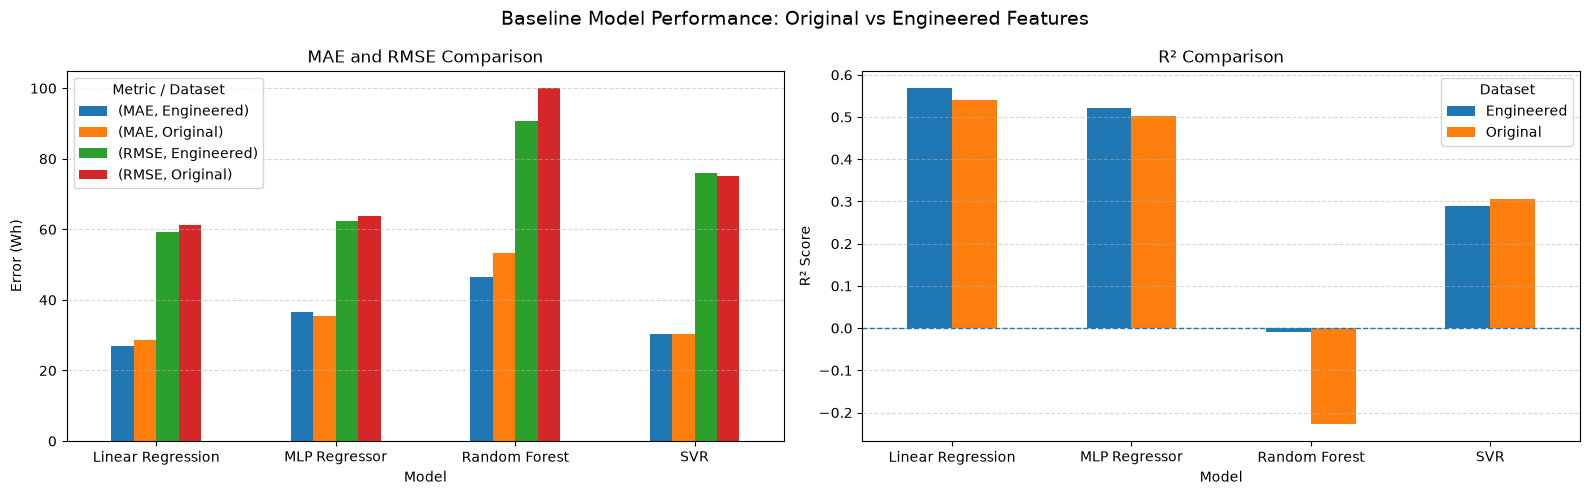

In [9]:

import matplotlib.pyplot as plt

display(comparison_results)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

error_comparison = comparison_results.pivot(
    index='Model',
    columns='Dataset',
    values=['MAE', 'RMSE']
)

error_comparison.plot(
    kind='bar',
    ax=axes[0],
    rot=0
)

axes[0].set_title('MAE and RMSE Comparison')
axes[0].set_ylabel('Error (Wh)')
axes[0].set_xlabel('Model')
axes[0].legend(title='Metric / Dataset')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

r2_comparison = comparison_results.pivot(
    index='Model',
    columns='Dataset',
    values='R2'
)

r2_comparison.plot(
    kind='bar',
    ax=axes[1],
    rot=0
)

axes[1].set_title('R² Comparison')
axes[1].set_ylabel('R² Score')
axes[1].set_xlabel('Model')
axes[1].axhline(y=0, linestyle='--', linewidth=1)
axes[1].legend(title='Dataset')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

fig.suptitle(
    'Baseline Model Performance: Original vs Engineered Features',
    fontsize=14
)

plt.tight_layout()
plt.show()


### Initial results

The baseline experiments provide an initial comparison of the four regression models across the original and engineered datasets.

Several observations can be made from the results:

- **Linear Regression** achieved the strongest overall baseline performance with the engineered features, obtaining the lowest MAE (26.88 Wh) and RMSE (59.17 Wh), as well as the highest R² score (0.570). The engineered features therefore appear to provide useful additional information for this model.

- **MLPRegressor** achieved competitive results. The engineered features produced a lower RMSE (62.46 Wh) and higher R² (0.521) than the original features (63.65 Wh and 0.502, respectively), although the original features resulted in a lower MAE (35.42 Wh compared with 36.52 Wh).

- **SVR** produced similar results across both datasets. The engineered features achieved a slightly lower MAE, while the original features produced a lower RMSE and a marginally higher R² score. This indicates that feature engineering had a limited and mixed effect on its baseline performance.

- **Random Forest Regressor** obtained the weakest baseline results. Its performance improved with the engineered features, but the R² score remained close to zero (-0.009), while the original-feature configuration produced a negative R² (-0.228).

Overall, Linear Regression emerged as the strongest baseline model, followed by MLPRegressor and SVR. Random Forest performed considerably worse than the other algorithms under their default configurations.

The results also suggest that feature engineering does not affect all algorithms in the same way. While Linear Regression benefited consistently, the improvements for the other models were smaller or varied depending on the evaluation metric.

These results provide an initial reference point for the experiments that follow. Further improvements may be possible through hyperparameter tuning.

#### Naive Baseline

In [10]:
y_pred_naive = X_val_engineered['Appliances']

persistence_val = pd.DataFrame([{
    'Model': 'Persistence (naive)',
    'MAE': mean_absolute_error(y_val_engineered, y_pred_naive),
    'RMSE': np.sqrt(mean_squared_error(y_val_engineered, y_pred_naive)),
    'R2': r2_score(y_val_engineered, y_pred_naive)
}])

display(persistence_val)

,Model,MAE,RMSE,R2
0,Persistence (naive),25.786249,65.513108,0.472554


### 8.4 Hyperparameter Tuning

After establishing the baseline performance of our regression models, we can now investigate whether further improvements can be achieved through hyperparameter tuning.

Hyperparameters control different aspects of how an algorithm learns and generates predictions. Their optimal values depend on the characteristics of the dataset and the relationships being modelled.

For this stage, we will use `GridSearchCV` to systematically evaluate different hyperparameter combinations. We will perform the experiments separately for the original and engineered datasets, allowing us to compare how each feature configuration responds to tuning.

Since our prediction task involves time-dependent observations, we will use `TimeSeriesSplit` for cross-validation. This ensures that each validation fold contains observations that occur after those used for training, preserving the chronological structure of the data.

In [11]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits=5)

#### 8.4.2 Support Vector Regression (SVR)

We will begin hyperparameter tuning with Support Vector Regression (SVR).

SVR uses several hyperparameters that influence how the model balances prediction accuracy and model complexity. For this experiment, we will focus on the following:

- `C`: Controls the trade-off between model complexity and the tolerance for prediction errors. Higher values place greater emphasis on minimizing training errors.
- `epsilon`: Defines the width of the tolerance margin around the predicted values. Errors within this margin are not penalized by the loss function.
- `gamma`: Controls the influence of individual training observations when using the RBF kernel.

We will use `GridSearchCV` to evaluate different parameter combinations through five-fold time-series cross-validation, separately for the original and engineered datasets.

#### Baseline Cross-Validation

Before tuning the SVR hyperparameters, we will evaluate the model using its default configuration and five-fold time-series cross-validation.

This provides a more reliable estimate of the model's performance across different chronological portions of the training data, rather than relying on a single validation split.

We will use `TimeSeriesSplit` to preserve the temporal order of observations and Root Mean Squared Error (RMSE) as our evaluation metric. The experiment will be performed separately on the original and engineered datasets, allowing us to compare their baseline cross-validation performance.

In [12]:
svr_cv_original = cross_val_score(
    models['SVR'],
    X_train_original,
    y_train_original,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

svr_cv_engineered = cross_val_score(
    models['SVR'],
    X_train_engineered,
    y_train_engineered,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

svr_cv_original = -svr_cv_original
svr_cv_engineered = -svr_cv_engineered

print("SVR - Original Features")
print("Fold RMSE:", svr_cv_original)
print("Mean RMSE:", svr_cv_original.mean())
print("Standard Deviation:", svr_cv_original.std())

print("\nSVR - Engineered Features")
print("Fold RMSE:", svr_cv_engineered)
print("Mean RMSE:", svr_cv_engineered.mean())
print("Standard Deviation:", svr_cv_engineered.std())


SVR - Original Features
Fold RMSE: [108.84724195  83.33675777  96.94156895  86.81473968  97.35792129]
Mean RMSE: 94.65964592635972
Standard Deviation: 8.983608336891088

SVR - Engineered Features
Fold RMSE: [107.57858069  82.96551912  96.52478636  86.59969582  96.79493269]
Mean RMSE: 94.09270293535558
Standard Deviation: 8.660777673141736


#### Hyperparameter Tuning

In [13]:
svr_param_grid = {
    'model__C': [1, 10],
    'model__epsilon': [0.1, 1],
    'model__gamma': ['scale', 'auto']
}

In [14]:
from sklearn.model_selection import GridSearchCV

svr_grid_original = GridSearchCV(
    estimator=models['SVR'],
    param_grid=svr_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs=4,
    verbose=1
)

svr_grid_engineered = GridSearchCV(
    estimator=models['SVR'],
    param_grid=svr_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs = 4,
    verbose=1
)

svr_grid_original.fit(X_train_original, y_train_original)

svr_grid_engineered.fit(X_train_engineered, y_train_engineered)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...del', SVR())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [1, 10], 'model__epsilon': [0.1, 1], 'model__gamma': ['scale', 'auto']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx

#### Inspecting Results

In [15]:
print("SVR - Original Features")
print("Best Parameters:", svr_grid_original.best_params_)
print("Best CV RMSE:", -svr_grid_original.best_score_)

print("\nSVR - Engineered Features")
print("Best Parameters:", svr_grid_engineered.best_params_)
print("Best CV RMSE:", -svr_grid_engineered.best_score_)

SVR - Original Features
Best Parameters: {'model__C': 10, 'model__epsilon': 0.1, 'model__gamma': 'scale'}
Best CV RMSE: 80.04564254118749

SVR - Engineered Features
Best Parameters: {'model__C': 10, 'model__epsilon': 1, 'model__gamma': 'scale'}
Best CV RMSE: 80.36369851287081


#### Validation Performance

After identifying the best hyperparameter configurations, we will evaluate the resulting models on their respective validation datasets.

This allows us to assess whether the improvements observed during cross-validation also translate to unseen observations. We will use MAE, RMSE and R² to compare the tuned models against their baseline counterparts.

In [16]:
svr_pred_original = svr_grid_original.best_estimator_.predict(
    X_val_original
)

svr_pred_engineered = svr_grid_engineered.best_estimator_.predict(
    X_val_engineered
)

svr_tuned_results = pd.DataFrame([
    {
        'Model': 'SVR',
        'Dataset': 'Original',
        'MAE': mean_absolute_error(y_val_original, svr_pred_original),
        'RMSE': np.sqrt(mean_squared_error(y_val_original, svr_pred_original)),
        'R2': r2_score(y_val_original, svr_pred_original)
    },
    {
        'Model': 'SVR',
        'Dataset': 'Engineered',
        'MAE': mean_absolute_error(y_val_engineered, svr_pred_engineered),
        'RMSE': np.sqrt(mean_squared_error(y_val_engineered, svr_pred_engineered)),
        'R2': r2_score(y_val_engineered, svr_pred_engineered)
    }
])

display(svr_tuned_results)

,Model,Dataset,MAE,RMSE,R2
0,SVR,Original,27.150198,64.896695,0.482432
1,SVR,Engineered,27.022104,65.081234,0.479485


**Observations**

Hyperparameter tuning resulted in a noticeable improvement in SVR performance on both dataset configurations.

Compared with the baseline models, the tuned configurations achieved lower MAE and RMSE values, alongside higher R² scores. The RMSE decreased by approximately 14% on both datasets, indicating that the selected hyperparameters helped reduce prediction errors.

When comparing the two feature configurations, the engineered dataset achieved slightly lower MAE and RMSE values, while the original dataset produced a marginally higher R² score. Overall, the differences between the two configurations remain relatively small.

These results suggest that hyperparameter tuning had a more substantial impact on SVR performance than the addition of the engineered features alone.

### 8.4.3 Random Forest Regressor

We will now investigate hyperparameter tuning with the Random Forest Regressor.

Random Forest uses several hyperparameters that influence how individual decision trees are constructed and how their predictions are combined. For this experiment, we will focus on the following:

- `n_estimators`: Determines the number of decision trees in the forest. Increasing this value can improve prediction stability, but also increases computational cost.
- `max_depth`: Controls the maximum depth of each decision tree. Limiting the depth can help prevent overfitting.
- `min_samples_split`: Specifies the minimum number of samples required to split an internal node. Higher values restrict the growth of individual trees.
- `min_samples_leaf`: Defines the minimum number of samples required in a leaf node. Increasing this value can produce smoother predictions and reduce overfitting.

We will use `GridSearchCV` to evaluate different parameter combinations through five-fold time-series cross-validation, separately for the original and engineered datasets.

#### Baseline Cross-Validation

In [17]:
rf_cv_original = cross_val_score(
    models['Random Forest'],
    X_train_original,
    y_train_original,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

rf_cv_engineered = cross_val_score(
    models['Random Forest'],
    X_train_engineered,
    y_train_engineered,
    cv=tscv,
    scoring='neg_root_mean_squared_error'
)

rf_cv_original = -rf_cv_original
rf_cv_engineered = -rf_cv_engineered

print("Random Forest - Original Features")
print("Fold RMSE:", rf_cv_original)
print("Mean RMSE:", rf_cv_original.mean())
print("Standard Deviation:", rf_cv_original.std())

print("\nRandom Forest - Engineered Features")
print("Fold RMSE:", rf_cv_engineered)
print("Mean RMSE:", rf_cv_engineered.mean())
print("Standard Deviation:", rf_cv_engineered.std())


Random Forest - Original Features
Fold RMSE: [105.0633056   87.17441477  86.46161157  80.29256544 107.90758685]
Mean RMSE: 93.379896847934
Standard Deviation: 11.001861107112255

Random Forest - Engineered Features
Fold RMSE: [ 98.15716048  77.72885718  74.23271958  71.54502474 102.55252957]
Mean RMSE: 84.84325830971326
Standard Deviation: 12.891233698221777


#### Hyperparameter Tuning

In [18]:

rf_param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 20],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}


In [19]:

rf_grid_original = GridSearchCV(
    estimator=models['Random Forest'],
    param_grid=rf_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs=4,
    verbose=1
)
rf_grid_engineered = GridSearchCV(
    estimator=models['Random Forest'],
    param_grid=rf_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs=4,
    verbose=1
)

rf_grid_original.fit(X_train_original, y_train_original)

rf_grid_engineered.fit(X_train_engineered, y_train_engineered)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 20], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know

#### Inspecting Results

In [20]:

print("Random Forest - Original Features")
print("Best Parameters:", rf_grid_original.best_params_)
print("Best CV RMSE:", -rf_grid_original.best_score_)

print("\nRandom Forest - Engineered Features")
print("Best Parameters:", rf_grid_engineered.best_params_)
print("Best CV RMSE:", -rf_grid_engineered.best_score_)

Random Forest - Original Features
Best Parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV RMSE: 79.47329740965836

Random Forest - Engineered Features
Best Parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV RMSE: 73.06925157602697


#### Validation Performance

In [21]:
rf_pred_original = rf_grid_original.best_estimator_.predict(
    X_val_original
)

rf_pred_engineered = rf_grid_engineered.best_estimator_.predict(
    X_val_engineered
)

rf_tuned_results = pd.DataFrame([
    {
        'Model': 'Random Forest',
        'Dataset': 'Original',
        'MAE': mean_absolute_error(y_val_original, rf_pred_original),
        'RMSE': np.sqrt(mean_squared_error(y_val_original, rf_pred_original)),
        'R2': r2_score(y_val_original, rf_pred_original)
    },
    {
        'Model': 'Random Forest',
        'Dataset': 'Engineered',
        'MAE': mean_absolute_error(y_val_engineered, rf_pred_engineered),
        'RMSE': np.sqrt(mean_squared_error(y_val_engineered, rf_pred_engineered)),
        'R2': r2_score(y_val_engineered, rf_pred_engineered)
    }
])

display(rf_tuned_results)


,Model,Dataset,MAE,RMSE,R2
0,Random Forest,Original,42.563647,77.080435,0.269853
1,Random Forest,Engineered,37.253880,70.150628,0.395237


**Observations**

Hyperparameter tuning resulted in a considerable improvement in Random Forest performance on both dataset configurations.

Compared with the baseline models, the tuned configurations achieved lower MAE and RMSE values, alongside substantially higher R² scores. The engineered dataset showed the largest improvement, with its validation RMSE decreasing by approximately 22.6%.

When comparing the two feature configurations, the engineered dataset consistently achieved better results across all three evaluation metrics. This suggests that the historical consumption and temporal features introduced during preprocessing provide useful information for the Random Forest model.

Overall, both hyperparameter tuning and feature engineering contributed to improving the predictive performance of Random Forest.

### **8.4.4 Multi-Layer Perceptron Regressor (MLPRegressor)**

MLPRegressor is a neural network model that learns relationships between input features and the target through interconnected layers of neurons. Several hyperparameters influence its architecture and learning process. For this experiment, we will focus on the following:

- `hidden_layer_sizes`: Determines the number of neurons in each hidden layer. Larger architectures can learn more complex relationships, but may also increase computational cost and the risk of overfitting.

- `alpha`: Controls the strength of L2 regularization, which helps prevent overfitting by penalizing large model weights.

- `learning_rate_init`: Determines the initial learning rate used by the optimizer. This influences how quickly the model adjusts its weights during training.

We will use GridSearchCV to evaluate different parameter combinations through five-fold time-series cross-validation, separately for the original and engineered datasets.

Since MLPRegressor is sensitive to the scale of input features, we will retain the StandardScaler in our pipeline throughout the experiments.

#### Baseline Cross-Validation

In [22]:
mlp_cv_original = cross_val_score(
    models['MLP Regressor'],
    X_train_original,
    y_train_original,
    cv=tscv,
    n_jobs=4,
    scoring='neg_root_mean_squared_error'
)

mlp_cv_engineered = cross_val_score(
    models['MLP Regressor'],
    X_train_engineered,
    y_train_engineered,
    cv=tscv,
    n_jobs=4,
    scoring='neg_root_mean_squared_error'
)

mlp_cv_original = -mlp_cv_original
mlp_cv_engineered = -mlp_cv_engineered

print("MLP Regressor - Original Features")
print("Fold RMSE:", mlp_cv_original)
print("Mean RMSE:", mlp_cv_original.mean())
print("Standard Deviation:", mlp_cv_original.std())

print("\nMLP Regressor - Engineered Features")
print("Fold RMSE:", mlp_cv_engineered)
print("Mean RMSE:", mlp_cv_engineered.mean())
print("Standard Deviation:", mlp_cv_engineered.std())


MLP Regressor - Original Features
Fold RMSE: [98.4587452  65.08456507 73.3138205  80.48735593 74.07676954]
Mean RMSE: 78.28425124825961
Standard Deviation: 11.21163392128687

MLP Regressor - Engineered Features
Fold RMSE: [107.25092945  89.12071889  89.00526086  91.61695966  82.15476327]
Mean RMSE: 91.82972642546751
Standard Deviation: 8.328025121981906


#### Hyperparameter Tuning

In [23]:

mlp_param_grid = {
    'model__hidden_layer_sizes': [(50,), (100,)],
    'model__activation': ['relu', 'tanh'],
    'model__alpha': [0.0001, 0.001],
    'model__learning_rate_init': [0.001, 0.01]
}

In [24]:
mlp_grid_original = GridSearchCV(
    estimator=models['MLP Regressor'],
    param_grid=mlp_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs=6,
    verbose=1
)

mlp_grid_engineered = GridSearchCV(
    estimator=models['MLP Regressor'],
    param_grid=mlp_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    refit=True,
    n_jobs=6,
    verbose=1
)


mlp_grid_original.fit(X_train_original, y_train_original)

mlp_grid_engineered.fit(X_train_engineered, y_train_engineered)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__activation': ['relu', 'tanh'], 'model__alpha': [0.0001, 0.001], 'model__hidden_layer_sizes': [(50,), (100,)], 'model__learning_rate_init': [0.001, 0.01]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",6
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``sco

#### Inspecting Results

In [25]:
print("MLP Regressor - Original Features")
print("Best Parameters:", mlp_grid_original.best_params_)
print("Best CV RMSE:", -mlp_grid_original.best_score_)

print("\nMLP Regressor - Engineered Features")
print("Best Parameters:", mlp_grid_engineered.best_params_)
print("Best CV RMSE:", -mlp_grid_engineered.best_score_)

MLP Regressor - Original Features
Best Parameters: {'model__activation': 'relu', 'model__alpha': 0.001, 'model__hidden_layer_sizes': (50,), 'model__learning_rate_init': 0.001}
Best CV RMSE: 74.07450999375173

MLP Regressor - Engineered Features
Best Parameters: {'model__activation': 'relu', 'model__alpha': 0.001, 'model__hidden_layer_sizes': (50,), 'model__learning_rate_init': 0.001}
Best CV RMSE: 80.81918242154626


#### Validation Performance

After identifying the best hyperparameter configurations, we will evaluate the resulting models on their respective validation datasets.

In [26]:
mlp_pred_original = mlp_grid_original.best_estimator_.predict(
    X_val_original
)

mlp_pred_engineered = mlp_grid_engineered.best_estimator_.predict(
    X_val_engineered
)

mlp_tuned_results = pd.DataFrame([
    {
        'Model': 'MLP Regressor',
        'Dataset': 'Original',
        'MAE': mean_absolute_error(y_val_original, mlp_pred_original),
        'RMSE': np.sqrt(mean_squared_error(y_val_original, mlp_pred_original)),
        'R2': r2_score(y_val_original, mlp_pred_original)
    },
    {
        'Model': 'MLP Regressor',
        'Dataset': 'Engineered',
        'MAE': mean_absolute_error(y_val_engineered, mlp_pred_engineered),
        'RMSE': np.sqrt(mean_squared_error(y_val_engineered, mlp_pred_engineered)),
        'R2': r2_score(y_val_engineered, mlp_pred_engineered)
    }
])

display(mlp_tuned_results)


,Model,Dataset,MAE,RMSE,R2
0,MLP Regressor,Original,28.546969,60.726188,0.546817
1,MLP Regressor,Engineered,34.064012,61.199946,0.539718


#### Observations

Hyperparameter tuning improved the MLP Regressor's performance on both datasets, as reflected by lower cross-validation and validation RMSE values.

Both searches selected the same network architecture, consisting of one hidden layer with `50 neurons` and `ReLU` activationan `alpha` value of `0.001` and an initial `learning rate` of `0.001`.

The original dataset achieved better results across all three validation metrics, indicating that the additional engineered features did not provide an advantage for the MLP Regressor.

Overall, hyperparameter tuning was beneficial, although the original feature set remained the better choice for this model.

### 8.5 Comparison of Tuned Models

After completing the individual experiments, we can now compare the performance of all four regression models.

For this comparison, we will use the validation results obtained during model development:
- **Linear Regression:** Baseline configuration, since no hyperparameter tuning was necessary.
- **SVR:** Best configuration identified through GridSearchCV.
- **Random Forest:** Best configuration identified through GridSearchCV.
- **MLP Regressor:** Best configuration identified through GridSearchCV.

We will compare the models separately for the original and engineered datasets, using MAE, RMSE and R². This will help us identify which algorithm provides the best predictive performance and whether feature engineering has a consistent impact across models.

In [27]:
linear_results = comparison_results[
    comparison_results['Model'] == 'Linear Regression'
]

final_comparison = pd.concat(
    [
        linear_results,
        svr_tuned_results,
        rf_tuned_results,
        mlp_tuned_results
    ],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    by=['Dataset', 'RMSE']
).reset_index(drop=True)

display(final_comparison)

,Model,Dataset,MAE,RMSE,R2
0,Linear Regression,Engineered,26.879569,59.169229,0.569757
1,MLP Regressor,Engineered,34.064012,61.199946,0.539718
2,SVR,Engineered,27.022104,65.081234,0.479485
3,Random Forest,Engineered,37.253880,70.150628,0.395237
4,MLP Regressor,Original,28.546969,60.726188,0.546817
5,Linear Regression,Original,28.624788,61.149673,0.540474
6,SVR,Original,27.150198,64.896695,0.482432
7,Random Forest,Original,42.563647,77.080435,0.269853


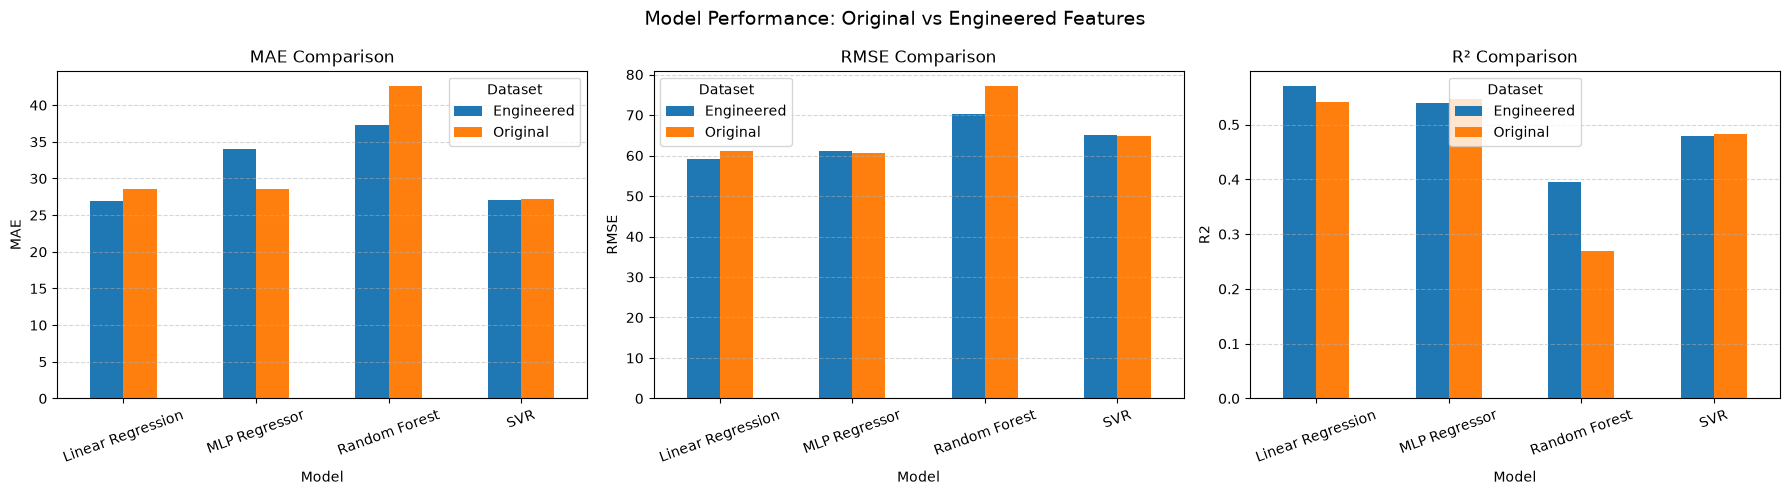

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ['MAE', 'RMSE', 'R2']
titles = ['MAE Comparison', 'RMSE Comparison', 'R² Comparison']

for ax, metric, title in zip(axes, metrics, titles):

    pivot = final_comparison.pivot(
        index='Model',
        columns='Dataset',
        values=metric
    )

    pivot.plot(kind='bar', ax=ax, rot=20)

    ax.set_title(title)
    ax.set_xlabel('Model')
    ax.set_ylabel(metric)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle(
    'Model Performance: Original vs Engineered Features',
    fontsize=14
)

plt.tight_layout()
plt.show()

#### Observations

The comparison shows that Linear Regression achieved the strongest overall performance, particularly when using the engineered dataset. It obtained the lowest RMSE (59.17) and highest R² (0.570) among all evaluated models. Its MAE was also practically identical to that of SVR.

For the original dataset, the MLP Regressor achieved the lowest RMSE and highest R², while SVR obtained the lowest MAE. However, their overall performance remained relatively close to that of Linear Regression.

Feature engineering had different effects depending on the algorithm. Linear Regression and Random Forest improved across all three evaluation metrics, while SVR showed mixed results. The MLP Regressor performed better with the original features, suggesting that the additional engineered variables were not equally beneficial to every model.

Random Forest consistently produced the weakest results, despite benefiting from both feature engineering and hyperparameter tuning.

Overall, Linear Regression using the engineered features provided the best balance of prediction error and explanatory performance. It will therefore be considered the leading candidate for final model selection.

### 8.6 Final Model Selection

Based on the validation results, we selected Linear Regression trained on the engineered dataset as our final model candidate.

It achieved the lowest RMSE (59.17) and highest R² (0.570) among all evaluated models, while also obtaining an MAE of 26.83.

Although the MLP Regressor performed slightly better on the original dataset, Linear Regression provided the strongest overall results when using the engineered features. Its simpler architecture also makes it easier to interpret and computationally efficient.

We will therefore use this configuration for the final evaluation on the previously reserved test set.

# 9. Final Model Evaluation

After selecting our final model, we will evaluate its performance on the previously reserved test set.

Before evaluation, we will retrain the selected model using the combined training and validation sets. This allows it to benefit from all available development data.

The test set will remain untouched during this process and will only be used for the final performance assessment.

In [29]:
from sklearn.base import clone

X_train_val = pd.concat(
    [X_train_engineered, X_val_engineered]
)

y_train_val = pd.concat(
    [y_train_engineered, y_val_engineered]
)

final_model = clone(models['Linear Regression'])

final_model.fit(X_train_val, y_train_val)

y_test_pred = final_model.predict(X_test_engineered)

final_results = pd.DataFrame([{
    'Model': 'Linear Regression',
    'Dataset': 'Engineered',
    'MAE': mean_absolute_error(y_test_engineered, y_test_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test_engineered, y_test_pred)),
    'R2': r2_score(y_test_engineered, y_test_pred)
}])

display(final_results)

,Model,Dataset,MAE,RMSE,R2
0,Linear Regression,Engineered,26.604524,60.495445,0.557811


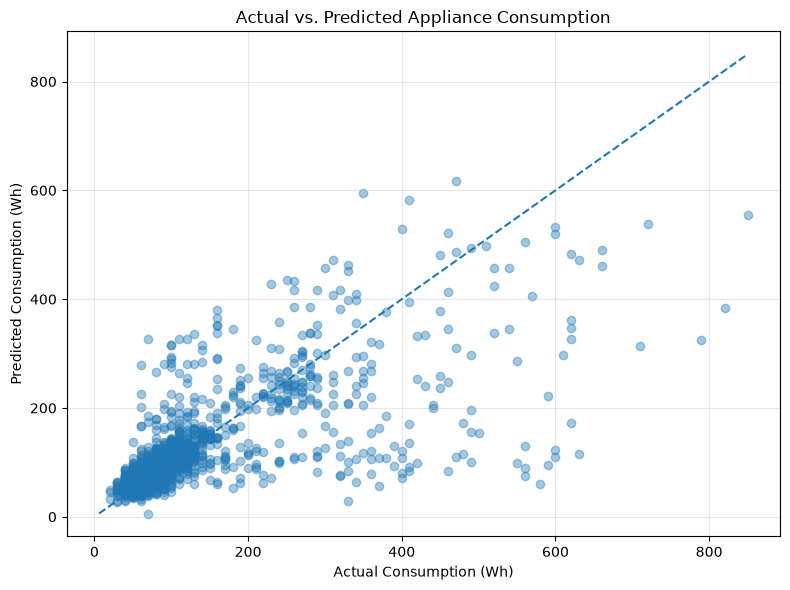

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_engineered,
    y_test_pred,
    alpha=0.4
)

min_value = min(y_test_engineered.min(), y_test_pred.min())
max_value = max(y_test_engineered.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.title('Actual vs. Predicted Appliance Consumption')
plt.xlabel('Actual Consumption (Wh)')
plt.ylabel('Predicted Consumption (Wh)')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

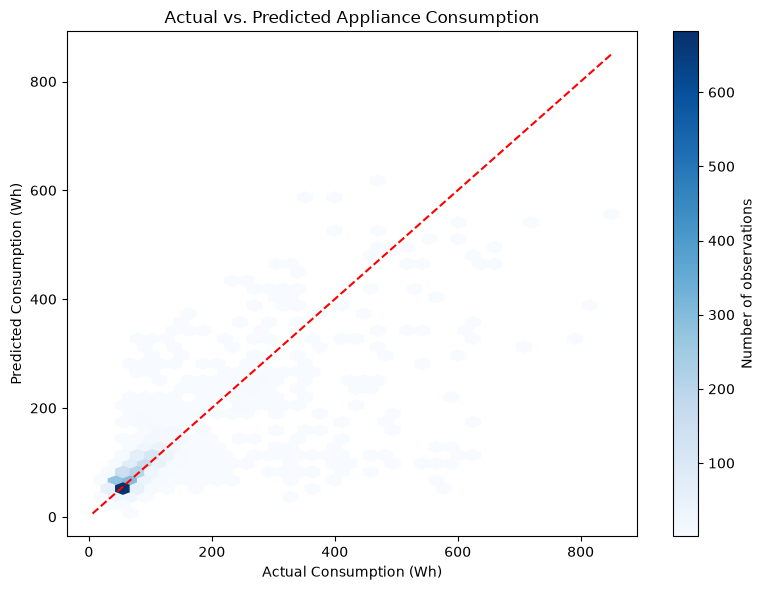

In [31]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    y_test_engineered,
    y_test_pred,
    gridsize=35,
    cmap='Blues',
    mincnt=1
)

min_value = min(y_test_engineered.min(), y_test_pred.min())
max_value = max(y_test_engineered.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    color='red'
)

plt.colorbar(label='Number of observations')

plt.title('Actual vs. Predicted Appliance Consumption')
plt.xlabel('Actual Consumption (Wh)')
plt.ylabel('Predicted Consumption (Wh)')

plt.tight_layout()
plt.show()

# 10. Conclusions and Discussion

The objective of this project was to investigate whether household appliance energy consumption could be predicted 10 minutes in advance using machine learning regression techniques. We approached this problem as a time-series prediction task, using the current and historical measurements to estimate consumption at the next observation.

We evaluated four regression algorithms: Linear Regression, Support Vector Regression, Random Forest Regressor and Multi-Layer Perceptron Regressor. Each model was trained and evaluated using two feature configurations: the original dataset and an engineered version containing additional historical consumption and temporal features.

The experiments demonstrated that **Linear Regression trained on the engineered dataset provided the strongest overall performance among the evaluated machine learning models**. On the validation set, it achieved an MAE of 26.88 Wh, an RMSE of 59.17 Wh and an R² score of 0.570. After retraining the model using the combined training and validation data, the final evaluation on the previously unseen test set produced an MAE of 26.60 Wh, an RMSE of 60.50 Wh and an R² score of 0.558.

The relatively small differences between validation and test performance suggest that the selected model generalizes reasonably consistently to unseen observations. However, its R² score indicates that a considerable proportion of the variation in appliance consumption remains unexplained.

An important part of our investigation was assessing the impact of feature engineering. We introduced lagged consumption values, a one-hour rolling average and temporal features representing the time of day. These additions improved the performance of Linear Regression across all three validation metrics. Random Forest also benefited from the engineered features, particularly after hyperparameter tuning. In contrast, MLPRegressor performed better with the original features, while SVR showed mixed results. This demonstrates that additional features do not necessarily improve every algorithm and that their usefulness depends on how each model represents relationships in the data.

We also compared our trained models against a simple persistence baseline, which predicts that the next consumption value will remain equal to the current one. Interestingly, this baseline achieved a lower MAE of 25.79 Wh, but a higher RMSE of 65.51 Wh and a lower R² score of 0.473 than the selected Linear Regression model on the validation set. This indicates that simply carrying the latest observation forward can produce smaller average absolute errors, while Linear Regression provides better overall explanatory performance and reduces the impact of larger prediction errors. The comparison also highlights the importance of including simple reference methods when evaluating time-series prediction models.

The final prediction plots revealed another limitation: although the selected model captures the general relationship between actual and predicted consumption, it tends to underestimate some of the highest consumption values. This suggests that the linear model has difficulty representing certain more complex patterns or sudden increases in appliance usage. The positively skewed distribution of the target variable and the presence of occasional consumption spikes may contribute to this behaviour.

Several limitations should therefore be considered when interpreting these results. The dataset covers approximately four and a half months of observations, which restricts the amount of historical information available. Furthermore, the experiments focus on predicting only the next 10-minute observation. The results should not automatically be interpreted as evidence that the same model would perform equally well over longer forecasting horizons.

Overall, the project demonstrates that short-term appliance energy consumption can be predicted to a reasonable extent using the available measurements and relatively simple regression techniques. Feature engineering provided measurable improvements for some models, while the comparison with the persistence baseline showed that model performance must be assessed from multiple perspectives rather than relying on a single metric. **Linear Regression with engineered features was therefore selected as the most suitable model among the evaluated alternatives**, although its performance leaves room for further improvement.